# Лабораторная 1

### Импорт

In [71]:
!pip install -r requirements.txt -q


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
RANDOM_STATE = 42

## Загрузка данных

In [73]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [74]:
print(f'Train: {train.shape}')
print(f'Test:  {test.shape}')
print()
print(train.dtypes)

Train: (28000, 30)
Test:  (7000, 29)

claim_id                              object
account_age_days                       int64
orders_before_claim                    int64
claims_before_claim                    int64
returns_before_claim                   int64
successful_orders_before_claim         int64
total_spent_before_claim             float64
average_order_amount_before_claim    float64
average_claim_amount_before_claim    float64
claim_rate_before_claim              float64
days_since_previous_order            float64
days_since_previous_claim            float64
claims_last_7_days                     int64
claims_last_30_days                    int64
orders_last_30_days                    int64
category                              object
order_amount                         float64
delivery_type                         object
payment_type                          object
seller_rating                        float64
days_from_order_to_delivery            int64
days_from_deliver

## EDA

In [75]:
print('Пропуски в train:')
print(train.isna().sum())

print(f'Дубликаты строк: {train.duplicated().sum()}')

print(f'\nРаспределение target:')
print(train['is_fraud'].value_counts())
print(train['is_fraud'].value_counts(normalize=True))

Пропуски в train:
claim_id                                0
account_age_days                        0
orders_before_claim                     0
claims_before_claim                     0
returns_before_claim                    0
successful_orders_before_claim          0
total_spent_before_claim                0
average_order_amount_before_claim       0
average_claim_amount_before_claim       0
claim_rate_before_claim                 0
days_since_previous_order               2
days_since_previous_claim            7756
claims_last_7_days                      0
claims_last_30_days                     0
orders_last_30_days                     0
category                                0
order_amount                            0
delivery_type                           0
payment_type                            0
seller_rating                           0
days_from_order_to_delivery             0
days_from_delivery_to_claim             0
order_amount_vs_user_average            0
reason          

Вывод по первичному анализу:

Данные загружены: train — 28 000 записей, 30 признаков; test — 7 000 записей, 29 признаков (без target). Пропуски только в двух колонках: days_since_previous_claim (7 756 — 27.7%, у пользователей без прошлых обращений) и days_since_previous_order (2 записи). Дубликатов нет.

Целевая переменная сильно несбалансирована: 91.75% обычных обращений против 8.25% мошеннических — соотношение примерно 11:1. Accuracy использовать как основную метрику нельзя: модель, которая всегда предсказывает «не мошенник», получит accuracy 0.92, но не поймает ни одного фрода. Основные метрики — Precision, Recall и PR-AUC, которые оценивают качество именно на редком классе.

In [76]:
cat_cols = train.select_dtypes(include=['object']).columns.tolist()
cat_cols.remove('claim_id')

bool_cols = train.select_dtypes(include=['bool']).columns.tolist()
num_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols.remove('is_fraud')

print(f'Категориальные ({len(cat_cols)}): {cat_cols}')
print(f'Бинарные ({len(bool_cols)}): {bool_cols}')
print(f'Числовые ({len(num_cols)}): {num_cols}')

Категориальные (4): ['category', 'delivery_type', 'payment_type', 'reason']
Бинарные (3): ['has_photo', 'has_video', 'verified']
Числовые (21): ['account_age_days', 'orders_before_claim', 'claims_before_claim', 'returns_before_claim', 'successful_orders_before_claim', 'total_spent_before_claim', 'average_order_amount_before_claim', 'average_claim_amount_before_claim', 'claim_rate_before_claim', 'days_since_previous_order', 'days_since_previous_claim', 'claims_last_7_days', 'claims_last_30_days', 'orders_last_30_days', 'order_amount', 'seller_rating', 'days_from_order_to_delivery', 'days_from_delivery_to_claim', 'order_amount_vs_user_average', 'requested_refund_amount', 'refund_ratio']


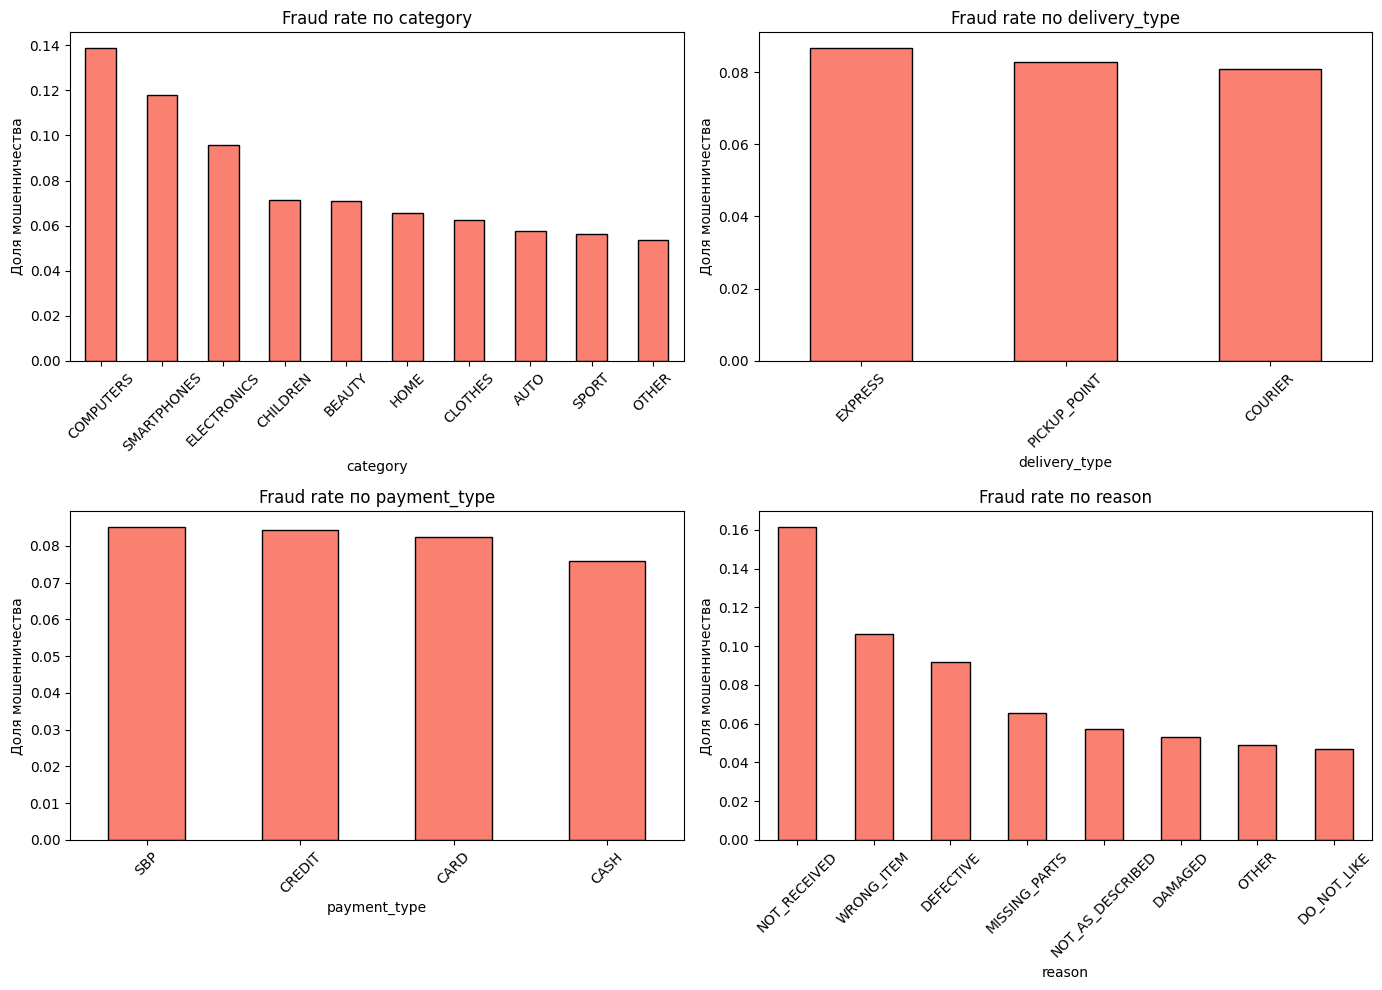


category
                 mean  count
category                    
COMPUTERS    0.138832   2946
SMARTPHONES  0.117772   3303
ELECTRONICS  0.095871   4287
CHILDREN     0.071469   1763
BEAUTY       0.071124   2348
HOME         0.065668   3472
CLOTHES      0.062621   4120
AUTO         0.057377   1952
SPORT        0.056208   1957
OTHER        0.053456   1852

delivery_type
                   mean  count
delivery_type                 
EXPRESS        0.086722   3886
PICKUP_POINT   0.082701  10931
COURIER        0.081013  13183

payment_type
                  mean  count
payment_type                 
SBP           0.085087   6699
CREDIT        0.084350   2786
CARD          0.082435  15115
CASH          0.075882   3400

reason
                      mean  count
reason                           
NOT_RECEIVED      0.161480   4756
WRONG_ITEM        0.106416   2556
DEFECTIVE         0.091935   3546
MISSING_PARTS     0.065434   3408
NOT_AS_DESCRIBED  0.057199   3549
DAMAGED           0.053297   553

In [77]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    fraud_rate = train.groupby(col)['is_fraud'].mean().sort_values(ascending=False)
    fraud_rate.plot(kind='bar', ax=ax, color='salmon', edgecolor='black')
    ax.set_title(f'Fraud rate по {col}')
    ax.set_ylabel('Доля мошенничества')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f'\n{col}')
    print(train.groupby(col)['is_fraud'].agg(['mean', 'count']).sort_values('mean', ascending=False))


Fraud rate сильно различается по категориям и причинам обращения. Самые рискованные категории — COMPUTERS (13.9%), SMARTPHONES (11.8%), ELECTRONICS (9.6%). Среди причин резко выделяется NOT_RECEIVED (16.1%) — в 2–3 раза выше остальных. delivery_type и payment_type почти не различаются по классам (8% у всех), слабые признаки. category и reason — сильные сигналы для модели.

In [78]:
print(train[num_cols].describe())

       account_age_days  orders_before_claim  claims_before_claim  \
count      28000.000000         28000.000000         28000.000000   
mean         662.615000             8.207214             2.444179   
std          496.167444             7.396791             2.886106   
min            3.000000             0.000000             0.000000   
25%          240.000000             3.000000             0.000000   
50%          565.000000             6.000000             2.000000   
75%          993.000000            11.000000             4.000000   
max         2119.000000            84.000000            33.000000   

       returns_before_claim  successful_orders_before_claim  \
count          28000.000000                    28000.000000   
mean               2.444179                        5.763036   
std                2.886106                        4.968944   
min                0.000000                        0.000000   
25%                0.000000                        2.000000   


Числовые признаки имеют разный масштаб: account_age_days до 2119, total_spent_before_claim до 1 млн, refund_ratio в диапазоне 0–1. Требуется масштабирование для линейной модели.

In [79]:
for col in bool_cols:
    print(train.groupby(col)['is_fraud'].agg('count'))

has_photo
False    17951
True     10049
Name: is_fraud, dtype: int64
has_video
False    25661
True      2339
Name: is_fraud, dtype: int64
verified
False     6403
True     21597
Name: is_fraud, dtype: int64


## Разделение

In [80]:
X = train.drop(columns=['claim_id', 'is_fraud'])
y = train['is_fraud']

X_test = test.drop(columns=['claim_id'])

print(f'X: {X.shape}, y: {y.shape}')
print(f'X_test: {X_test.shape}')

X: (28000, 28), y: (28000,)
X_test: (7000, 28)


In [81]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'Train: {X_train.shape}, Val: {X_val.shape}')
print(y_train.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))

Train: (22400, 28), Val: (5600, 28)
is_fraud
0    0.917545
1    0.082455
Name: proportion, dtype: float64
is_fraud
0    0.9175
1    0.0825
Name: proportion, dtype: float64


##  Dummy

In [82]:
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_val)
y_proba_dummy = dummy.predict_proba(X_val)[:, 1]
print(f'Accuracy:  {accuracy_score(y_val, y_pred_dummy):.4f}')
print(f'Precision: {precision_score(y_val, y_pred_dummy, zero_division=0):.4f}')
print(f'Recall:{recall_score(y_val, y_pred_dummy, zero_division=0):.4f}')
print(f'F1:{f1_score(y_val, y_pred_dummy, zero_division=0):.4f}')
print(f'ROC-AUC:{roc_auc_score(y_val, y_proba_dummy):.4f}')
print(f'PR-AUC:{average_precision_score(y_val, y_proba_dummy):.4f}')
print(confusion_matrix(y_val, y_pred_dummy))

Accuracy:  0.9175
Precision: 0.0000
Recall:0.0000
F1:0.0000
ROC-AUC:0.5000
PR-AUC:0.0825
[[5138    0]
 [ 462    0]]


Baseline: DummyClassifier всегда предсказывает «не фрод». Accuracy 0.9175 — это доля нормальных обращений. Precision, Recall, F1 = 0 — модель не находит ни одного мошенника. ROC-AUC 0.5 (случайно), PR-AUC 0.0825 (равен доле фрода). Это точка отсчёта.

## 3 Модели

In [83]:
cat_features = cat_cols
bool_features = bool_cols
num_features = num_cols

In [84]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [85]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [86]:
preprocessor_lr = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features),
    ('bool', 'passthrough', bool_features)
])


In [87]:
pipe_lr = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
])

pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_val)
y_proba_lr = pipe_lr.predict_proba(X_val)[:, 1]
print(f'Accuracy:{accuracy_score(y_val, y_pred_lr):.4f}')
print(f'Precision:{precision_score(y_val, y_pred_lr):.4f}')
print(f'Recall:{recall_score(y_val, y_pred_lr):.4f}')
print(f'F1:{f1_score(y_val, y_pred_lr):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_val, y_proba_lr):.4f}')
print(f'PR-AUC:{average_precision_score(y_val, y_proba_lr):.4f}')
print(confusion_matrix(y_val, y_pred_lr))

Accuracy:0.6932
Precision:0.1684
Recall:0.6905
F1:0.2708
ROC-AUC: 0.7504
PR-AUC:0.2503
[[3563 1575]
 [ 143  319]]


In [88]:
X_train_cb = X_train.copy()
X_val_cb = X_val.copy()


In [89]:
for c in cat_features:
    X_train_cb[c] = X_train_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)
for c in num_features:
    median_val = X_train_cb[c].median()
    X_train_cb[c] = X_train_cb[c].fillna(median_val)
    X_val_cb[c] = X_val_cb[c].fillna(median_val)



In [90]:
cb_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    random_seed=RANDOM_STATE,
    verbose=0
)

In [91]:
cb_model.fit(X_train_cb, y_train, cat_features=cat_features)
y_pred_cb = cb_model.predict(X_val_cb)
y_proba_cb = cb_model.predict_proba(X_val_cb)[:, 1]
print(f'Accuracy:{accuracy_score(y_val, y_pred_cb):.4f}')
print(f'Precision:{precision_score(y_val, y_pred_cb):.4f}')
print(f'Recall:{recall_score(y_val, y_pred_cb):.4f}')
print(f'F1:{f1_score(y_val, y_pred_cb):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_val, y_proba_cb):.4f}')
print(f'PR-AUC:{average_precision_score(y_val, y_proba_cb):.4f}')
print(confusion_matrix(y_val, y_pred_cb))

Accuracy:0.9171
Precision:0.4643
Recall:0.0281
F1:0.0531
ROC-AUC: 0.7555
PR-AUC:0.2368
[[5123   15]
 [ 449   13]]


In [98]:
pipe_rf = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('model', RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

pipe_rf.fit(X_train, y_train)

y_pred_rf = pipe_rf.predict(X_val)
y_proba_rf = pipe_rf.predict_proba(X_val)[:, 1]

print('Random Forest')
print(f'Accuracy:{accuracy_score(y_val, y_pred_rf):.4f}')
print(f'Precision:{precision_score(y_val, y_pred_rf):.4f}')
print(f'Recall{recall_score(y_val, y_pred_rf):.4f}')
print(f'F1:{f1_score(y_val, y_pred_rf):.4f}')
print(f'ROC-AUC:{roc_auc_score(y_val, y_proba_rf):.4f}')
print(f'PR-AUC: {average_precision_score(y_val, y_proba_rf):.4f}')
print(confusion_matrix(y_val, y_pred_rf))

Random Forest
Accuracy:0.8834
Precision:0.2710
Recall0.2446
F1:0.2571
ROC-AUC:0.7331
PR-AUC: 0.2118
[[4834  304]
 [ 349  113]]


## Подбор thresholds

In [93]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

def analyze_threshold(y_true, y_proba, thresholds, model_name):
    print(f'{model_name}')
    print(f'{"Thr":<6}{"Precision":<12}{"Recall":<10}{"F1":<10}{"FP":<8}{"FN":<8}')
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        p = precision_score(y_true, y_pred, zero_division=0)
        r = recall_score(y_true, y_pred, zero_division=0)
        f = f1_score(y_true, y_pred, zero_division=0)
        print(f'{t:<6}{p:<12.4f}{r:<10.4f}{f:<10.4f}{fp:<8}{fn:<8}')
    print()

analyze_threshold(y_val, y_proba_lr, thresholds, 'LogisticRegression')
analyze_threshold(y_val, y_proba_cb, thresholds, 'CatBoost')
analyze_threshold(y_val, y_proba_rf, thresholds, 'RandomForest')

LogisticRegression
Thr   Precision   Recall    F1        FP      FN      
0.1   0.0829      1.0000    0.1532    5108    0       
0.2   0.0900      0.9827    0.1649    4591    8       
0.3   0.1085      0.9242    0.1942    3509    35      
0.4   0.1340      0.8312    0.2308    2482    78      
0.5   0.1684      0.6905    0.2708    1575    143     

CatBoost
Thr   Precision   Recall    F1        FP      FN      
0.1   0.1845      0.5498    0.2762    1123    208     
0.2   0.3126      0.2944    0.3032    299     326     
0.3   0.3665      0.1277    0.1894    102     403     
0.4   0.4030      0.0584    0.1021    40      435     
0.5   0.4643      0.0281    0.0531    15      449     

RandomForest
Thr   Precision   Recall    F1        FP      FN      
0.1   0.0908      0.9805    0.1662    4535    9       
0.2   0.1226      0.8420    0.2140    2785    73      
0.3   0.1671      0.6255    0.2637    1441    173     
0.4   0.2148      0.4156    0.2832    702     270     
0.5   0.2710      0.24

In [94]:
FINAL_THRESHOLD = 0.2

In [95]:
X_full = pd.concat([X_train, X_val]).reset_index(drop=True)
y_full = pd.concat([y_train, y_val]).reset_index(drop=True)

X_full_cb = X_full.copy()
X_test_cb = X_test.copy()

for c in cat_features:
    X_full_cb[c] = X_full_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)
for c in num_features:
    median_val = X_full_cb[c].median()
    X_full_cb[c] = X_full_cb[c].fillna(median_val)
    X_test_cb[c] = X_test_cb[c].fillna(median_val)

final_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    random_seed=RANDOM_STATE,
    verbose=0,
    class_weights=[1, 11]
)

final_model.fit(X_full_cb, y_full, cat_features=cat_features)


CatBoostClassifier(class_weights=[1, 11], depth=6, iterations=500, learning_rate=0.05, random_seed=42, verbose=0)

In [96]:
fraud_proba_test = final_model.predict_proba(X_test_cb)[:, 1]
is_fraud_prediction = (fraud_proba_test >= FINAL_THRESHOLD).astype(int)

print(f'Распределение предсказаний:')
print(pd.Series(is_fraud_prediction).value_counts())
print(f' {fraud_proba_test.mean():.4f}')

Распределение предсказаний:
1    5056
0    1944
Name: count, dtype: int64
 0.3524


In [97]:
predictions = pd.DataFrame({
    'claim_id': test['claim_id'],
    'fraud_probability': fraud_proba_test,
    'is_fraud_prediction': is_fraud_prediction
})
predictions.to_csv('predictions.csv', index=False)
print(predictions.head(10))

   claim_id  fraud_probability  is_fraud_prediction
0  C0028001           0.227854                    1
1  C0028002           0.191059                    0
2  C0028003           0.113091                    0
3  C0028004           0.179454                    0
4  C0028005           0.212449                    1
5  C0028006           0.517407                    1
6  C0028007           0.326809                    1
7  C0028008           0.519177                    1
8  C0028009           0.122766                    0
9  C0028010           0.423920                    1


Почему CatBoost: лучший ROC-AUC (0.7555) и максимальный F1 = 0.303 при пороге 0.2.

Лучше baseline: Dummy даёт F1 = 0, ROC-AUC 0.5. CatBoost ловит 29% мошенников.

Лучше LogReg: LogReg даёт лучший PR-AUC (0.2503), но её F1 = 0.271 ниже, и FP в 5 раз больше.

Лучше RandomForest: RF даёт F1 = 0.283 при пороге 0.4, но ROC-AUC 0.7331 — худший из трёх.

Слабые стороны: Precision 0.31 — из 3 срабатываний только 1 верный. Много FP (299) и FN (326).

Чаще ошибается: FN больше FP (326 против 299), пропускает мошенников.

Threshold 0.2: выбран по максимуму F1. Сдвиг в сторону большего Recall был бы логичен для антифрода, но тогда FP растёт и ручная модерация не справляется.